In [2]:
import pyvisa
import time
rm = pyvisa.ResourceManager()
res = rm.list_resources()
print(res)

('USB0::0x1AB1::0x04CE::DS1ZA205020654::INSTR', 'USB0::0x1AB1::0x04CE::DS1ZA164256910::INSTR', 'ASRL1::INSTR', 'ASRL3::INSTR', 'ASRL4::INSTR')


In [3]:
inst_id = "DS1ZA"
index = [i for i in range(len(res)) if inst_id in res[i]]
print(index)

[0, 1]


In [87]:

inst = rm.open_resource(res[index[0]])


In [88]:
print(inst.read_termination)
inst.read_termination='\n'

None


In [89]:
inst.query("*IDN?")

'RIGOL TECHNOLOGIES,DS1104Z,DS1ZA183315127,00.04.04'

In [90]:
t_scale = inst.query_ascii_values(":TIM:SCAL?")
v_scale = inst.query_ascii_values(":CHAN1:SCAL?")
v_offset = inst.query_ascii_values(":CHAN1:OFFS?")
inst.write(":ACQ:MDEPth 30000")
mdep = inst.query_ascii_values(":ACQ:MDEP?")
t_scale, v_scale, v_offset, mdep
#inst.query_ascii_values(":TIM:OFFS?")

([0.005], [0.2], [-0.508], [30000.0])

In [91]:
import matplotlib.pyplot as plt
import numpy as np

inst.write(":TIM:SCAL 0.02")
inst.write(":TIM:OFFS 0.0")

time.sleep(1)
for i in range(1):
    inst.write(":STOP")
    inst.write(':WAV:SOUR CHAN2')
    inst.write(':WAV:MODE raw')
    inst.write(':WAV:FORM byte')
    # inst.write(':WAV:STAR 1')
    
    inst.write(':WAV:STOP 30000')
    inst.write(":WAV:DATA?")
    data = inst.read_raw()
    wvf_format, wvf_type, wvf_points, count, xinc, xorigin, xref, yinc, yorigin, yref = inst.query_ascii_values(":WAV:PRE?")
    print(wvf_format, wvf_type, wvf_points, count, xinc, xorigin, xref, yinc, yorigin, yref)
    data = np.frombuffer(data, dtype = "uint8",offset = 12)[:-1]
    print(len(data))
    print(wvf_points)
    #inst.write(":RUN")

0.0 2.0 30000.0 1.0 8e-06 0.0 0.0 0.004886718 -2.0 103.0
29999
30000.0


In [92]:
wvf_format, wvf_type, wvf_points, count, xinc, xorigin, xref, yinc, yorigin, yref = inst.query_ascii_values(":WAV:PRE?")

In [93]:
import numpy as np
import matplotlib.pyplot as plt

inst.write(':WAV:SOUR CHAN2')
inst.write(':WAV:MODE raw')
inst.write(':WAV:FORM byte')
inst.write(':WAV:STOP 3000')
inst.write(":WAV:DATA?")
data = inst.read_raw()
data = np.frombuffer(data, dtype = "uint8",offset = 12)[:-1]

103.0 -2.0 [101. 101. 102. ...  95.  95.  95.]
8e-06 0.0 0.0


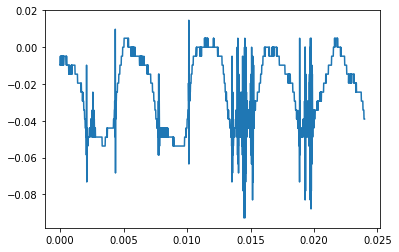

In [95]:
print(yref, yorigin, data - yorigin)
fig, ax = plt.subplots()
print(xinc, xorigin, xref)
wvf_points = len(data)
t = np.arange(0, wvf_points * xinc, xinc) + xorigin
t = t#[:-1]
ax.plot(t, (data - yorigin - yref) * yinc)
voltage = (data - yorigin - yref) * yinc

In [97]:
import pyaudio

CHUNK = len(voltage)
MAX_INT = 2**16
RATE = 44100
pa = pyaudio.PyAudio()
stream = pa.open(
    format=pyaudio.paInt16,
    channels=1,
    rate=RATE,
    frames_per_buffer=CHUNK,
    input=False,
    output_device_index=2,
    output=True
)
buffer = np.zeros(CHUNK * 2)
fir = np.zeros(CHUNK * 2)
fir[:(2*CHUNK)] = 1.
fir /= fir.sum()
fir_last = fir
MAX_INT = 2.**16
avg_freq_buffer = np.zeros(CHUNK)
obj = -np.inf

for i in range(500):
    inst.write(":WAV:DATA?")
    data = inst.read_raw()
    data = np.frombuffer(data, dtype="uint8", offset=12)[:-1]
    voltage = (data - yorigin - yref) * yinc
    resampled = scipy.signal.resample(voltage, int(RATE * xinc * wvf_points))
    audio_data = np.array(np.round_(resampled * MAX_INT), dtype=np.int16)
    string_audio_data = audio_data.tobytes()
    stream.write(string_audio_data)

stream.stop_stream()
stream.close()
pa.terminate()

ValueError: offset must be non-negative and no greater than buffer length (2)

1199 1199
[  6   8   2 ... 252 252 252]


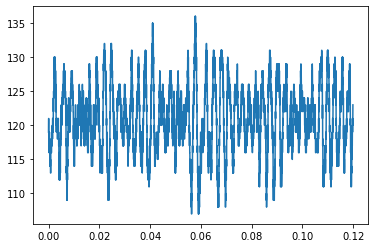

In [60]:
inst.write(":WAV:DATA?")
data = inst.read_raw()
data = np.frombuffer(data, dtype="uint8", offset=12)[:-1]
time.sleep(0.06)
inst.write(":WAV:DATA?")
data2 = inst.read_raw()
data2 = np.frombuffer(data2, dtype="uint8", offset=12)[:-1]
print(len(data), len(data2))
fig, ax = plt.subplots()
ax.plot(np.arange(0, wvf_points * xinc * 2, xinc), np.concatenate([data, data2]))


In [72]:
import scipy.signal
inst.write(":WAV:DATA?")
data = inst.read_raw()
data = np.frombuffer(data, dtype="uint8", offset=12)[:-1]
voltage = (data - yorigin - yref) * yinc
resampled = scipy.signal.resample(voltage, int(RATE * xinc * wvf_points))


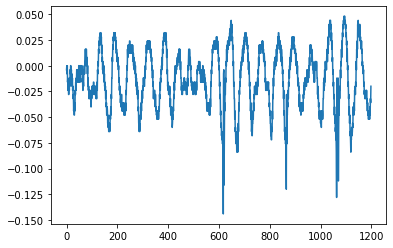

In [73]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(resampled)